# Leakage-Free Diabetic Retinopathy Grading: the complete pipeline

**Authors:** Akshai Krishna KP, Mohammed Azhar Sait, Karthik Krishna K, Rohit A

This notebook walks through the **whole project in the order it was done**:

1. environment setup,
2. the literature audit,
3. dataset download,
4. data preparation (cache, duplicate audit, grouped splits),
5. a smoke test,
6. **Stage A**: 10 paper baselines on APTOS (validation),
7. **Stage B**: tuning the top 3 (validation),
8. **Stage C**: the scope decision,
9. **Stage D**: EyePACS pretraining,
10. **Stage E**: APTOS fine-tuning (classifier and regressor heads),
11. **Stage F**: ensemble selection with cross-fitted thresholds (validation only),
12. **Stage G**: the **one-time** test evaluation, plus external IDRiD and Messidor-2,
13. **Stage H**: baselines on test, cross-dataset results and statistics,
14. **Stage I**: the packaged model and inference on new images,
15. interpretability (Grad-CAM), and building the paper.

### The rules this project follows
* Only genuine fundus photographs with their original grades: no synthetic, GAN or pseudo-labelled data.
  Augmentation of real images is allowed.
* The test split is **never** used for training, tuning, model selection or threshold fitting.
  It is read exactly once, after everything was frozen.
* No test images are removed or altered to improve scores. Official test sets are kept as they are.

### How to use this notebook
Some steps take **hours** on a GPU: the full project took about 2 days on an RTX 4060 Laptop.
Every expensive step is therefore controlled by a switch in the next code cell:

* With all switches `False` (the default), the notebook **does not retrain anything**. It reads the
  saved results in `experiments/`, `reports/` and `results/` and recomputes or visualises every
  analysis step from them. A full run takes a few minutes.
* Setting a switch to `True` runs that stage for real, with the exact command used in the project.

Run it from the repository root or from `notebooks/`. The working directory is fixed automatically.

## 1. Environment setup

The project uses **uv** for Python: Python 3.12, PyTorch 2.11 with CUDA 12.8, timm, scikit-learn and grad-cam.
Before opening the notebook, run this once in a terminal:

```bash
uv sync                    # creates .venv from pyproject.toml + uv.lock (exact versions)
uv run jupyter lab         # or open the notebook in VS Code with the .venv kernel
```

In [1]:
# ---- Stage switches: set to True only for the stages you want to actually (re)run ---------------
RUN_DOWNLOAD    = False   # download APTOS / EyePACS / Messidor-2 grades (~90 GB, needs Kaggle token)
RUN_PREPARE     = False   # build the 512 px cache, run the duplicate audit, write grouped splits (~1 h)
RUN_SMOKE_TEST  = False   # 1-epoch training run on IDRiD to check that the pipeline works (~2 min)
RUN_BASELINES   = False   # Stage A: 10 paper baselines on APTOS, validation only (~10 h)
RUN_TUNING      = False   # Stage B: tuning rounds 1 and 2 for the top 3 models (~8 h)
RUN_EYEPACS     = False   # Stage D: EyePACS pretraining of the top 3 (~5 h)
RUN_FINETUNE    = False   # Stage E: 6 APTOS fine-tunes from EyePACS weights (~2 h)
RUN_SELECTION   = False   # Stage F: ensemble selection over 770 candidates (validation only)
RUN_FINAL_TEST  = False   # Stage G: ONE-TIME test evaluation. It was done once; leave False.
RUN_BASELINE_TEST = False # Stage H: one-time test evaluation of the frozen baselines
RUN_INFERENCE_DEMO = True # Stage I: grade a few images with the packaged ensemble (needs weights)
RUN_PAPER_BUILD = False   # rebuild the paper figures and PDF (needs Tectonic)

In [2]:
# ---- Imports and paths ---------------------------------------------------------------------------
import json, os, subprocess, sys, shlex, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # cosmetic tqdm notice in Jupyter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Work from the repository root, whether the notebook was opened from the root or from notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))                 # makes `import src...` work
sys.path.insert(0, str(ROOT / "scripts"))     # makes `import best_model` work

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

EXP, REP, PLOTS, CKPT = ROOT / "experiments", ROOT / "reports", ROOT / "results" / "plots", ROOT / "checkpoints"
GRADES = ["No DR", "Mild", "Moderate", "Severe", "PDR"]
print("Repository root:", ROOT.name)

Repository root: DR_Detection


In [3]:
# ---- Helper: run a shell command with live output -------------------------------------------------
# Every stage is driven by the same scripts used in the project (scripts/*.py, scripts/*.sh), so the
# notebook reproduces exactly what was done instead of a re-written copy of the code.
def run(cmd: str, enabled: bool = True):
    if not enabled:
        print(f"[skipped: switch is False]  $ {cmd}")
        return
    print(f"$ {cmd}", flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"command failed with exit code {p.returncode}: {cmd}")


def load_json(p):
    return json.loads(Path(p).read_text())

In [4]:
# ---- Check the hardware -----------------------------------------------------------------------------
# Training used mixed precision (AMP) and channels-last memory format on an 8 GB RTX 4060 Laptop GPU.
import torch
print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0),
          f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")

PyTorch 2.11.0+cu128 | CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU (7.6 GB)


## 2. Literature audit: which models to reproduce

The starting point is the team's **15-paper survey** (`docs/literature_survey.pdf`). Each paper was checked
for whether its model can be rebuilt and trained on public data. **10 models** were selected for the
five-class task.

`configs/models.yaml` stores the default settings for each model. Its `source` field marks every setting
as either **paper** (stated by the authors) or **ours** (not stated, so we chose it and documented it).
That labelling is why the work is called an *adapted reproduction*, not an exact one.

In [5]:
# ---- The 10 reproduced models and where each setting comes from -----------------------------------
import yaml
cfg = yaml.safe_load((ROOT / "configs" / "models.yaml").read_text())
rows = []
for name, c in cfg.items():
    t = c.get("train") or {}
    rows.append(dict(model=name, paper=c.get("paper"), size=t.get("size", "-"),
                     enhancement=t.get("enhancement", "-"), loss=t.get("loss", "-"),
                     settings_source=c.get("source", "")[:110]))
pd.DataFrame(rows)

,model,paper,size,enhancement,loss,settings_source
0,effb3_se,P4,384,ben_graham,wce,"arch: paper, preprocessing: paper (crop + Gaus..."
1,inception_v3,P7,384,raw,wce,"arch: paper, init: paper (ImageNet), early_sto..."
2,densenet169,P14,384,raw,wce,"arch: paper, everything_else: ours"
3,resnet50_rf,P11,384,raw,wce,"arch: paper, finetune_epochs: paper (20), drop..."
4,hybrid_svm,P6,-,-,-,"features: paper (1000+1000 FC outputs, frozen)..."
5,light2stage,P10,227,raw,wce,"input: paper (227), optimizer: paper (SGDM, mo..."
6,mil_resnet18,P12,512,graham_rim,wce,"preprocessing: paper (crop, 512, Graham colour..."
7,p8_vgg16,P8,384,agc_p8,wce,enhancement: paper code (AGC alpha=0.4 + V-cha...
8,mscnn_lstm,P15,224,clahe,wce,"input: paper (224), preprocessing: paper ([0,1..."
9,vit_b16,P14,224,raw,wce,"arch: paper (ViT-B/16), everything_else: ours"


## 3. Dataset download

| Dataset | Images | Role | Access |
|---|---|---|---|
| **APTOS 2019** | 3,662 | main train / validation / test | Kaggle competition |
| **EyePACS** | 35,126 (train set) | pretraining + cross-dataset | Kaggle competition |
| **IDRiD** | 516 | external test | IEEE DataPort (manual) |
| **Messidor-2** | 1,744 | external test | ADCIS request (manual) + Kaggle grades |

Credentials are needed:
* a Kaggle API token in `~/.kaggle/`;
* manual downloads for IDRiD and Messidor-2, placed in `data/raw/`.

The datasets are **not** in the git repository because their licences forbid redistribution.

In [6]:
# ---- Download (skipped by default) ------------------------------------------------------------------
run("bash scripts/download_datasets.sh >> data/raw/download.log 2>&1", RUN_DOWNLOAD)
run("uv run python scripts/check_datasets.py", RUN_DOWNLOAD)   # verifies file counts and labels

[skipped: switch is False]  $ bash scripts/download_datasets.sh >> data/raw/download.log 2>&1
[skipped: switch is False]  $ uv run python scripts/check_datasets.py


## 4. Data preparation: cache, duplicate audit and grouped splits

`scripts/prepare_data.py` does three things.

**4.1 Cache.** Every image is retina-cropped, padded to a square and resized to 512 px. Each model then
reads identical geometry, and training is much faster than decoding full-size photos.

**4.2 Duplicate audit (leakage control).** Public DR datasets contain near-duplicate photos, and some
have *conflicting* grades. If one copy lands in train and the other in test, the test score is inflated.

* **Method:** a green-channel high-pass "vessel fingerprint" at 96 px, using only the central 80% of the
  retina radius. Pairs are compared by correlation, matches at r ≥ 0.99 are flagged, and union-find
  builds the clusters.
* **Why the rim is excluded:** EyePACS cameras imprint the same rim pattern on every image, which falsely
  linked 16 different eyes.
* **Conflicting grades:** clusters whose copies disagree on the grade are excluded, since they have no
  valid label.
* **Same grade:** the copies are collapsed to one image.

**4.3 Splits.** The split is 70/15/15, stratified by grade and **grouped** with `StratifiedGroupKFold`
(seed 42):
* by **patient** for EyePACS (both eyes stay together);
* by **exam** for Messidor-2;
* by **duplicate cluster** for APTOS.

IDRiD keeps its official test set.

In [7]:
# ---- Prepare data (skipped by default; the resulting split files are in data/splits/) -------------
run("uv run python scripts/prepare_data.py --datasets idrid messidor2 aptos eyepacs --workers 12", RUN_PREPARE)

[skipped: switch is False]  $ uv run python scripts/prepare_data.py --datasets idrid messidor2 aptos eyepacs --workers 12


**Images per split** (`all` = external datasets evaluated as a whole):

,aptos,eyepacs,idrid,messidor2
split,,,,
test,525,5272,103,264
train,2437,24586,324,1213
val,524,5268,81,263


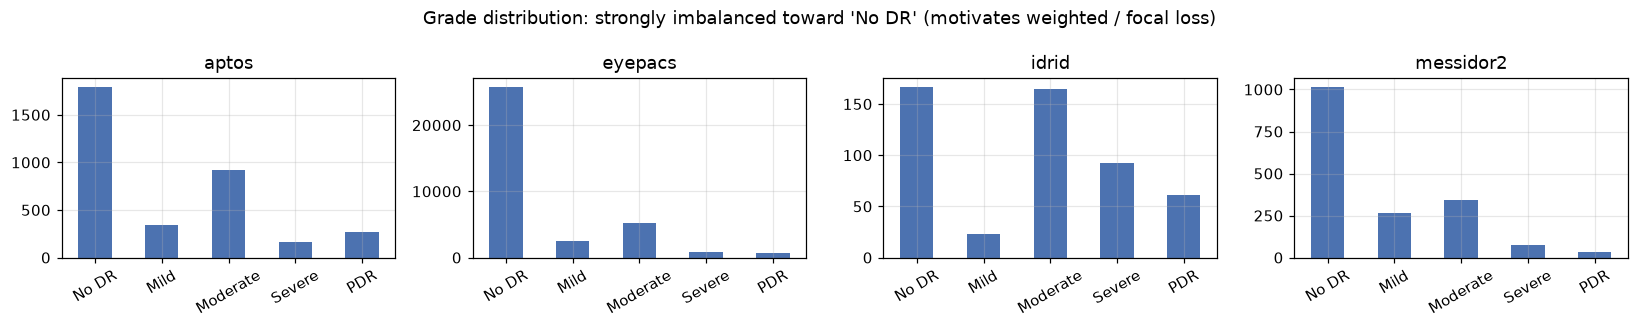

In [8]:
# ---- 4.3 Split sizes and grade distribution per dataset -------------------------------------------------
# data/splits/<dataset>_5class.csv has one row per usable image: uid, label (ICDR grade), group, split.
splits = {d: pd.read_csv(ROOT / "data" / "splits" / f"{d}_5class.csv")
          for d in ["aptos", "eyepacs", "idrid", "messidor2"]}
tab = pd.concat({d: s.groupby("split").size() for d, s in splits.items()}, axis=1).fillna(0).astype(int)
display(Markdown("**Images per split** (`all` = external datasets evaluated as a whole):"))
display(tab)

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, (d, s) in zip(axes, splits.items()):
    s.label.value_counts().sort_index().reindex(range(5), fill_value=0).plot.bar(ax=ax, color="#4C72B0")
    ax.set_title(d); ax.set_xticklabels(GRADES, rotation=30); ax.set_xlabel("")
fig.suptitle("Grade distribution: strongly imbalanced toward 'No DR' (motivates weighted / focal loss)")
plt.tight_layout(); plt.show()

In [9]:
# ---- Grouping check: no group (patient / exam / duplicate cluster) crosses two splits --------------
# This is the actual leakage test: if any group appeared in both train and test, the split would be invalid.
for d, s in splits.items():
    n_split_per_group = s.groupby("group").split.nunique()
    print(f"{d:10s} groups: {len(n_split_per_group):6d} | groups spanning >1 split: {(n_split_per_group > 1).sum()}")

aptos      groups:   3486 | groups spanning >1 split: 0
eyepacs    groups:  17563 | groups spanning >1 split: 0
idrid      groups:    508 | groups spanning >1 split: 0
messidor2  groups:    872 | groups spanning >1 split: 0


In [10]:
# ---- 4.2 Duplicate audit results -------------------------------------------------------------------
# *_duplicate_pairs.csv : every pair with correlation >= 0.99 (uid_a, uid_b, corr, labels)
# *_duplicates.csv      : cluster membership and whether the cluster has conflicting grades
rows = []
for d in ["aptos", "eyepacs", "idrid", "messidor2"]:
    pairs = pd.read_csv(ROOT / "data" / "metadata" / f"{d}_duplicate_pairs.csv")
    dup = pd.read_csv(ROOT / "data" / "metadata" / f"{d}_duplicates.csv")
    rows.append(dict(dataset=d, pairs=len(pairs), images_in_clusters=len(dup),
                     clusters=dup.dup_cluster.nunique() if len(dup) else 0,
                     conflicting_images_excluded=int(dup.label_conflict.sum()) if len(dup) else 0))
pd.DataFrame(rows)

,dataset,pairs,images_in_clusters,clusters,conflicting_images_excluded
0,aptos,148,270,131,79
1,eyepacs,0,40,11,25
2,idrid,6,12,6,6
3,messidor2,4,8,4,0


corr(duplicate pair)  = 1.000   (>= 0.99 -> same photo)
corr(unrelated image) = 0.221


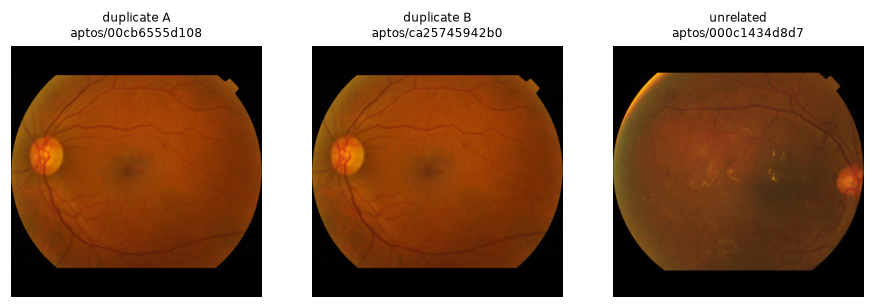

In [11]:
# ---- Re-implementation of the duplicate fingerprint on one real duplicate pair ----------------------
# Same function as scripts/prepare_data.py::_highpass_vec. It uses the green channel minus a Gaussian blur
# (keeping vessels and lesions), restricted to the inner 80% of the retina, then z-normalised.
import cv2
from prepare_data import _highpass_vec

pairs = pd.read_csv(ROOT / "data" / "metadata" / "aptos_duplicate_pairs.csv")
aptos = splits["aptos"].set_index("uid")
meta = pd.read_csv(ROOT / "data" / "metadata" / "aptos.csv").set_index("uid")
cache_dir = ROOT / "data" / "processed" / "aptos" / "512"

def cache_path(uid):
    return cache_dir / (uid.split("/")[1] + ".jpg")

a, b = pairs.iloc[0].uid_a, pairs.iloc[0].uid_b
c = next(u for u in aptos.index if u not in (a, b))            # an unrelated image for comparison
if cache_path(a).exists():
    va, vb, vc = (_highpass_vec(str(cache_path(u))) for u in (a, b, c))
    r = lambda x, y: float(np.dot(x, y) / len(x))
    print(f"corr(duplicate pair)  = {r(va, vb):.3f}   (>= 0.99 -> same photo)")
    print(f"corr(unrelated image) = {r(va, vc):.3f}")
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
    for k, u in enumerate((a, b, c)):
        ax[k].imshow(cv2.cvtColor(cv2.imread(str(cache_path(u))), cv2.COLOR_BGR2RGB)); ax[k].axis("off")
        ax[k].set_title(("duplicate A", "duplicate B", "unrelated")[k] + f"\n{u}", fontsize=8)
    plt.show()
else:
    print("Image cache not present (run the preparation step); skipping the visual check.")

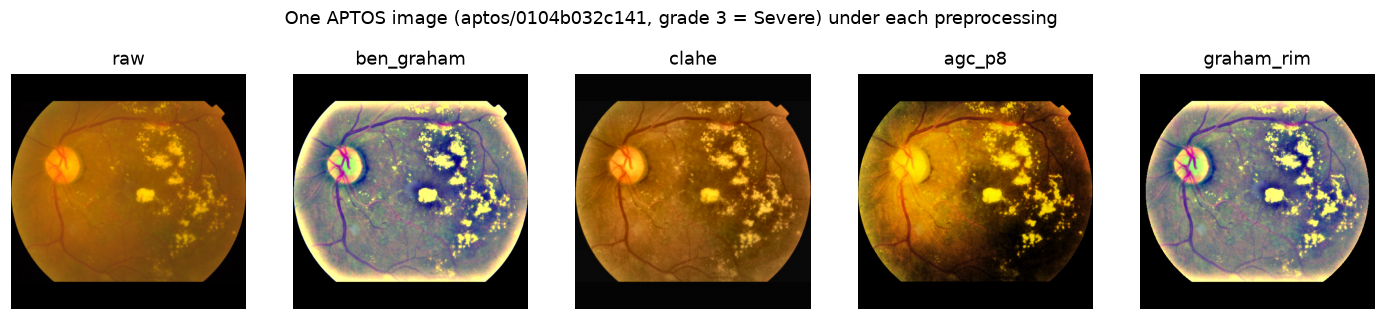

In [12]:
# ---- Preprocessing variants used by the different papers -----------------------------------------------
# raw: crop only | ben_graham: subtract local mean colour (P4 and others) | clahe: local contrast (P15)
# agc_p8: adaptive gamma + CDF equalisation (P8) | graham_rim: Ben Graham + dark outer rim (P12)
from src.preprocessing.retina import ENHANCEMENTS
uid = aptos.index[aptos.label == 3][0]          # a 'Severe' example
if cache_path(uid).exists():
    img = cv2.cvtColor(cv2.imread(str(cache_path(uid))), cv2.COLOR_BGR2RGB)
    names = ["raw", "ben_graham", "clahe", "agc_p8", "graham_rim"]
    fig, ax = plt.subplots(1, len(names), figsize=(16, 3.4))
    for a_, n in zip(ax, names):
        out = ENHANCEMENTS[n](img)
        a_.imshow(out if out.ndim == 3 else out, cmap=None if out.ndim == 3 else "gray"); a_.set_title(n); a_.axis("off")
    plt.suptitle(f"One APTOS image ({uid}, grade 3 = Severe) under each preprocessing"); plt.show()

## 5. Smoke test

A one-epoch run on the small IDRiD set checks the full path (data loading, model, AMP training, validation
metrics, checkpointing) before committing GPU-hours.

In [13]:
run("uv run python scripts/train.py --model effb3_se --dataset idrid --epochs 1 --run_name smoke", RUN_SMOKE_TEST)

[skipped: switch is False]  $ uv run python scripts/train.py --model effb3_se --dataset idrid --epochs 1 --run_name smoke


## 6. Stage A: APTOS baselines for all 10 models (validation only)

Each model is trained with its paper-derived defaults (`configs/models.yaml`), with the same splits, the same
cache and the same metric code for all models.

* **Selection score:** `S = 0.5 × (QWK + macro-F1)`. QWK rewards getting the grade *order* right;
  macro-F1 makes sure the rare grades (Severe, PDR) count.
* **Early stopping and checkpointing** use S on the **validation** split.
* **Feature models (P11 RF, P6 SVM):** a classifier is fitted on CNN features.
* **P10:** a two-stage lightweight CNN (DR / no DR, then severity).

In [14]:
# ---- Run the baseline queue (skipped by default) --------------------------------------------------
run("bash scripts/run_queue.sh > experiments/queue_aptos.log 2>&1", RUN_BASELINES)

[skipped: switch is False]  $ bash scripts/run_queue.sh > experiments/queue_aptos.log 2>&1


In [15]:
# ---- Collect every run's validation summary from experiments/<run>/summary.json ---------------------------
def summaries():
    out = []
    for f in sorted(EXP.glob("*/summary.json")):
        s = load_json(f); v = s.get("val", {})
        out.append(dict(run=f.parent.name, model=s.get("model"), paper=s.get("paper"), dataset=s.get("dataset"),
                        task=s.get("task"), best_epoch=s.get("best_epoch"),
                        val_acc=v.get("accuracy"), val_qwk=v.get("qwk"), val_macro_f1=v.get("macro_f1"),
                        val_score=0.5 * (v.get("qwk", np.nan) + v.get("macro_f1", np.nan)),
                        params_M=(s.get("params") or np.nan) / 1e6, train_min=(s.get("train_time_s") or np.nan) / 60))
    return pd.DataFrame(out)

S = summaries()
base = S[(S.dataset == "aptos") & ~S.run.str.startswith(("tune__", "ft__")) & (S.task == "5class")]
base = base.sort_values("val_score", ascending=False).reset_index(drop=True)
base

,run,model,paper,dataset,task,best_epoch,val_acc,val_qwk,val_macro_f1,val_score,params_M,train_min
0,resnet50_rf__aptos__5class__raw_384_s42,resnet50_rf,P11,aptos,5class,20.0,0.887,0.937,0.773,0.855,23.518,10.894
1,densenet169__aptos__5class__raw_384_s42,densenet169,P14,aptos,5class,23.0,0.876,0.933,0.764,0.849,12.493,21.626
2,effb3_se__aptos__5class__ben_graham_384_s42,effb3_se,P4,aptos,5class,10.0,0.861,0.926,0.737,0.831,11.000,15.030
3,resnet50_rf__aptos__5class,resnet50_rf,P11,aptos,5class,NaN,0.876,0.916,0.745,0.831,23.518,0.020
4,inception_v3__aptos__5class__raw_384_s42,inception_v3,P7,aptos,5class,7.0,0.870,0.917,0.732,0.825,21.796,7.778
5,vit_b16__aptos__5class__raw_224_s42,vit_b16,P14,aptos,5class,20.0,0.855,0.910,0.727,0.819,85.803,13.944
6,p8_vgg16__aptos__5class__agc_p8_384_s42,p8_vgg16,P8,aptos,5class,7.0,0.853,0.916,0.714,0.815,134.289,25.048
7,mil_resnet18__aptos__5class__graham_rim_512_s42,mil_resnet18,P12,aptos,5class,18.0,0.855,0.890,0.695,0.792,11.247,39.694
8,hybrid_svm__aptos__5class,hybrid_svm,P6,aptos,5class,NaN,0.824,0.864,0.593,0.729,18.314,0.180
9,mscnn_lstm__aptos__5class__clahe_224_s42,mscnn_lstm,P15,aptos,5class,47.0,0.767,0.820,0.450,0.635,1.918,5.519


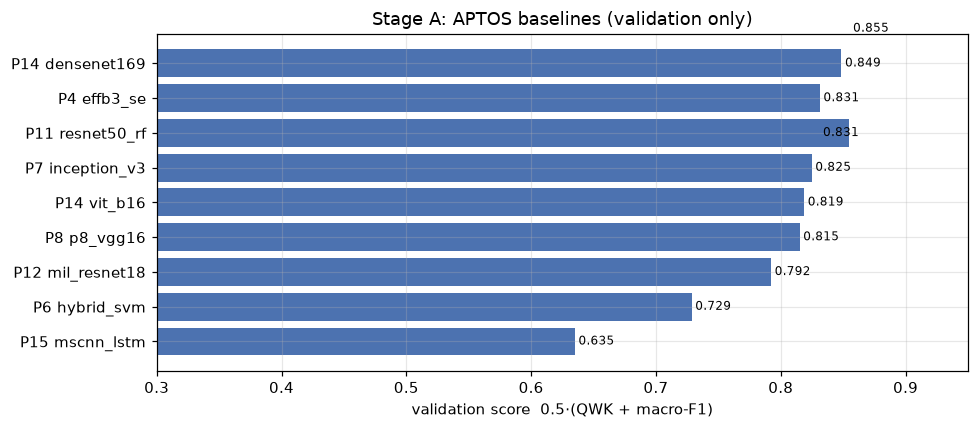

In [16]:
# ---- Visual ranking of the baselines (validation score S) -------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4))
lbl = base.paper + " " + base.model
ax.barh(lbl[::-1], base.val_score[::-1], color="#4C72B0")
for y, v in enumerate(base.val_score[::-1]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("validation score  0.5·(QWK + macro-F1)"); ax.set_xlim(0.3, 0.95)
ax.set_title("Stage A: APTOS baselines (validation only)"); plt.tight_layout(); plt.show()

## 7. Stage B: tuning the top 3 (validation only)

The top 3 baselines were **ResNet-50 (P11), DenseNet-169 (P14) and EfficientNet-B3+SE (P4)**. One factor was
changed at a time, so each change in score can be attributed to it:

* **Round 1:**
  * resolution 512 px;
  * the other preprocessing;
  * focal loss;
  * a √-balanced sampler.
* **Round 2:**
  * two more ResNet-50 seeds, to measure **run-to-run noise**;
  * a longer ResNet-50 schedule (40 epochs);
  * focal loss combined with 512 px for DenseNet.

A change counts as a real improvement only if it is larger than the seed noise.

In [17]:
run("bash scripts/tune_queue.sh", RUN_TUNING)
run("bash scripts/tune_round2.sh", RUN_TUNING)

[skipped: switch is False]  $ bash scripts/tune_queue.sh
[skipped: switch is False]  $ bash scripts/tune_round2.sh


In [18]:
# ---- Tuning deltas vs each model's baseline -----------------------------------------------------
tune = S[S.run.str.startswith("tune__")].copy()
tune["base_model"] = tune.run.str.split("__").str[1]
tune["variant"] = tune.run.str.split("__").str[2]
base_score = base.set_index("model").val_score
base_score = base_score[~base_score.index.duplicated()]
tune["baseline_score"] = tune.base_model.map(base_score)
tune["delta"] = tune.val_score - tune.baseline_score
display(tune[["base_model", "variant", "val_acc", "val_qwk", "val_macro_f1", "val_score", "delta"]]
        .sort_values(["base_model", "delta"], ascending=[True, False]).reset_index(drop=True))

# Run-to-run noise: same ResNet-50 config, seeds 42 / 1 / 2.
seeds = pd.concat([base[base.model == "resnet50_rf"].val_score.head(1),
                   tune[tune.variant.isin(["seed1", "seed2"])].val_score])
print(f"ResNet-50 seed noise: mean {seeds.mean():.3f}, std {seeds.std():.3f} (n={len(seeds)})")

,base_model,variant,val_acc,val_qwk,val_macro_f1,val_score,delta
0,densenet169,focal,0.880,0.930,0.776,0.853,4.709e-03
1,densenet169,res512,0.880,0.933,0.770,0.851,2.903e-03
2,densenet169,focal_res512,0.874,0.923,0.777,0.850,1.091e-03
3,densenet169,sqrtsamp,0.855,0.929,0.754,0.841,-7.117e-03
4,densenet169,enh_ben_graham,0.874,0.921,0.741,0.831,-1.747e-02
5,effb3_se,res512,0.876,0.921,0.766,0.844,1.257e-02
6,effb3_se,sqrtsamp,0.866,0.920,0.725,0.823,-8.454e-03
7,effb3_se,enh_raw,0.861,0.923,0.719,0.821,-1.031e-02
8,effb3_se,focal,0.857,0.913,0.720,0.816,-1.491e-02
9,resnet50_rf,ep40,0.885,0.925,0.786,0.855,3.914e-04


ResNet-50 seed noise: mean 0.852, std 0.003 (n=3)


## 8. Stage C: scope decision

**Finding:** all tuning changes fell within about ±0.017 of their baselines. That is roughly the size of the
seed noise, so no single tweak was clearly better.

**Decision:** the original plan was a full 10-model EyePACS queue plus a referable-DR track (Track B). The
project goal was the **best possible five-class model**, so effort went into the two remaining levers with
real potential instead:

1. **More data:** pretraining on EyePACS, which has about 10× APTOS's training images and comes from many
   sites.
2. **Ensembling:** combining different architectures and heads, with thresholds fitted on validation.

## 9. Stage D: EyePACS pretraining

The top 3 architectures were trained on EyePACS:
* 24,586 training and 5,268 validation images, grouped by patient;
* the APTOS-tuned settings;
* 12 epochs with patience 4. One EyePACS epoch already has about 10× the updates of an APTOS epoch.

The script still lists the original full queue. Only its first four runs were used.

In [19]:
E = "--dataset eyepacs --epochs 12 --patience 4"
run(f"uv run python scripts/train.py --model effb3_se {E} --size 512 --batch_size 8 --accum 2", RUN_EYEPACS)
run(f"uv run python scripts/train.py --model densenet169 {E} --loss focal", RUN_EYEPACS)
run(f"uv run python scripts/train.py --model resnet50_rf {E}", RUN_EYEPACS)

[skipped: switch is False]  $ uv run python scripts/train.py --model effb3_se --dataset eyepacs --epochs 12 --patience 4 --size 512 --batch_size 8 --accum 2
[skipped: switch is False]  $ uv run python scripts/train.py --model densenet169 --dataset eyepacs --epochs 12 --patience 4 --loss focal
[skipped: switch is False]  $ uv run python scripts/train.py --model resnet50_rf --dataset eyepacs --epochs 12 --patience 4


In [20]:
S[S.dataset == "eyepacs"][["run", "model", "best_epoch", "val_acc", "val_qwk", "val_macro_f1", "val_score", "train_min"]]

,run,model,best_epoch,val_acc,val_qwk,val_macro_f1,val_score,train_min
1,densenet169__eyepacs__5class__raw_384_s42,densenet169,10.0,0.822,0.770,0.579,0.675,73.598
3,effb3_se__eyepacs__5class__ben_graham_512_s42,effb3_se,10.0,0.830,0.815,0.616,0.715,122.343
20,resnet50_rf__eyepacs__5class,resnet50_rf,NaN,0.841,0.767,0.561,0.664,0.721
21,resnet50_rf__eyepacs__5class__raw_384_s42,resnet50_rf,12.0,0.838,0.772,0.585,0.678,53.559


## 10. Stage E: fine-tuning on APTOS with two kinds of head

DR grades are **ordered**, so each EyePACS model was fine-tuned on APTOS in two forms.

* **Classifier:** five softmax outputs. It is better for accuracy and macro-F1.
* **Regressor:** one output trained with SmoothL1 against the grade number. It makes smaller errors in grade
  distance, which suits QWK.
  * For metrics, the score is turned into class probabilities with a Gaussian (σ = 0.5).
  * The raw score is saved for the ensemble.

**Fine-tune settings:** learning rate 1e-4, 15 epochs, patience 6, a 1-epoch warm-up and a cosine schedule.
Only weights whose shapes match are loaded, so the regression head starts fresh.

In [21]:
run("bash scripts/run_best.sh", RUN_FINETUNE)   # 6 fine-tunes, then an automatic selection

[skipped: switch is False]  $ bash scripts/run_best.sh


,run,best_epoch,val_acc,val_qwk,val_macro_f1,val_score,train_min
0,ft__effb3_cls__aptos,4.0,0.876,0.929,0.748,0.838,11.274
1,ft__densenet_cls__aptos,6.0,0.868,0.926,0.736,0.831,8.239
2,ft__resnet50_cls__aptos,7.0,0.866,0.918,0.732,0.825,6.127
3,ft__densenet_reg__aptos,13.0,0.849,0.938,0.696,0.817,9.979
4,ft__resnet50_reg__aptos,3.0,0.834,0.922,0.678,0.800,4.373
5,ft__effb3_reg__aptos,8.0,0.823,0.933,0.660,0.797,15.138


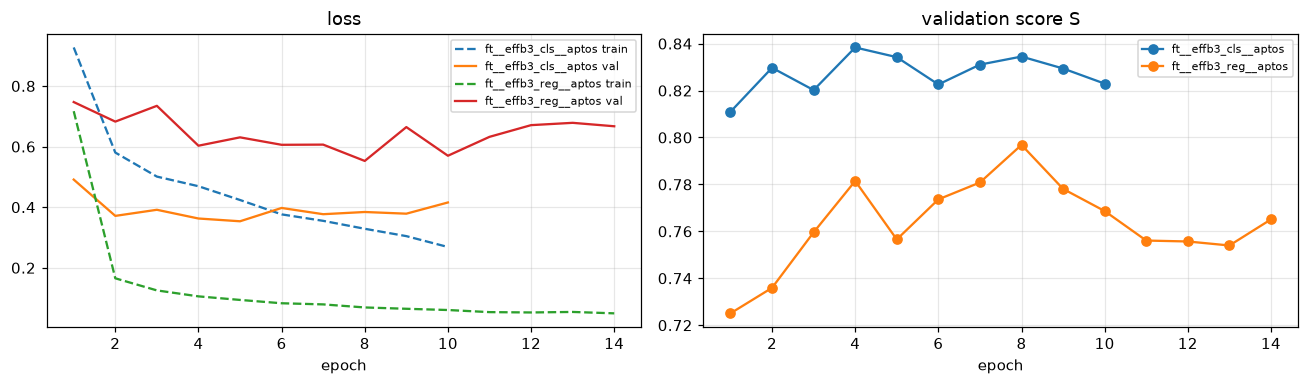

In [22]:
# ---- Fine-tune results on validation -------------------------------------------------------------
ft = S[S.run.str.startswith("ft__")][["run", "best_epoch", "val_acc", "val_qwk", "val_macro_f1", "val_score", "train_min"]]
display(ft.sort_values("val_score", ascending=False).reset_index(drop=True))

# Training curves of the two EfficientNet-B3 fine-tunes, which end up in the final ensemble.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for run_name in ["ft__effb3_cls__aptos", "ft__effb3_reg__aptos"]:
    h = pd.read_csv(EXP / run_name / "history.csv")
    ax[0].plot(h.epoch, h.train_loss, "--", label=f"{run_name} train"); ax[0].plot(h.epoch, h.val_loss, label=f"{run_name} val")
    ax[1].plot(h.epoch, h.score, marker="o", label=run_name)
ax[0].set_title("loss"); ax[1].set_title("validation score S"); ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch")
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## 11. Stage F: ensemble selection (validation only)

Choosing an ensemble *and* fitting its thresholds on the same validation images over-fits. The selection
guards against this.

1. Every candidate model predicts validation with **4-flip test-time augmentation**. The predictions are
   cached in `experiments/best_aptos/preds/`.
2. Each model gives a **grade score**: the regressor output, or the expected grade Σ k·p_k for a classifier.
3. All subsets of 1–4 candidates are formed (385). Each is tried under two decision rules, giving
   **770 candidates**:
   * `thr`: average the scores and cut them at 4 thresholds found by coordinate search;
   * `argmax`: average the probabilities and take the most likely class.
4. Each `thr` candidate is scored by **3 × repeated 5-fold cross-fitting**: thresholds are fitted on 4/5 of
   validation and scored on the remaining 1/5, so the score never sees its own fitted thresholds.
5. The winner's thresholds are refitted on all of validation and saved to `selection.json`.

The next cells **recompute the winner's cross-fitted score live** from the cached validation predictions,
using the same functions as `scripts/best_model.py`.

In [23]:
E = "checkpoints"
run(f'uv run python scripts/best_model.py --dataset aptos --max_size 4 --members "{E}/ft__*__aptos.pt" '
    f'{E}/inception_v3__aptos__5class__raw_384_s42.pt {E}/resnet50_rf__aptos__5class__raw_384_s42.pt '
    f'{E}/tune__densenet169__focal__aptos.pt {E}/tune__effb3_se__res512__aptos.pt', RUN_SELECTION)

[skipped: switch is False]  $ uv run python scripts/best_model.py --dataset aptos --max_size 4 --members "checkpoints/ft__*__aptos.pt" checkpoints/inception_v3__aptos__5class__raw_384_s42.pt checkpoints/resnet50_rf__aptos__5class__raw_384_s42.pt checkpoints/tune__densenet169__focal__aptos.pt checkpoints/tune__effb3_se__res512__aptos.pt


In [24]:
# ---- The frozen selection -----------------------------------------------------------------------------
sel = load_json(EXP / "best_aptos" / "selection.json")
print("members   :", *[Path(m).stem for m in sel["members"]], sep="\n   ")
print("rule      :", sel["mode"])
print("thresholds:", np.round(sel["thresholds"], 2))
print(f"candidates evaluated: {len(sel['candidates'])}   cross-fitted validation score: {sel['cv_val_score']:.4f}")

members   :
   ft__effb3_cls__aptos
   ft__effb3_reg__aptos
   inception_v3__aptos__5class__raw_384_s42
   tune__densenet169__focal__aptos
rule      : thr
thresholds: [0.64 1.51 2.74 3.09]
candidates evaluated: 770   cross-fitted validation score: 0.8776


In [25]:
# ---- Recompute the selection score from the cached validation predictions (CPU, ~seconds) -----------------
from best_model import cv_score, fit_thresholds, sel_score, cut

PRED = EXP / "best_aptos" / "preds"
def member(stem, split="aptos_val"):
    d = np.load(PRED / f"{stem}__{split}_tta4.npz", allow_pickle=True)
    return d["y"], d["prob"], d["raw"]

stems = [Path(m).stem for m in sel["members"]]
ys, probs, raws = zip(*(member(s) for s in stems))
y = ys[0]; assert all((yy == y).all() for yy in ys)           # same images, same order
s_ens = np.mean(raws, axis=0)                                   # averaged grade score of the 4 members

score, _ = cv_score(y, s_ens)                                    # 3 x 5-fold cross-fitted thresholds
print(f"recomputed cross-fitted score = {score:.4f}   (selection.json: {sel['cv_val_score']:.4f})")

# Single members under the same procedure: the ensemble should beat each one of them.
for st, r in zip(stems, raws):
    print(f"  {st:45s} {cv_score(y, r)[0]:.4f}")

recomputed cross-fitted score = 0.8776   (selection.json: 0.8776)


  ft__effb3_cls__aptos                          0.8404


  ft__effb3_reg__aptos                          0.8176


  inception_v3__aptos__5class__raw_384_s42      0.7962


  tune__densenet169__focal__aptos               0.8452


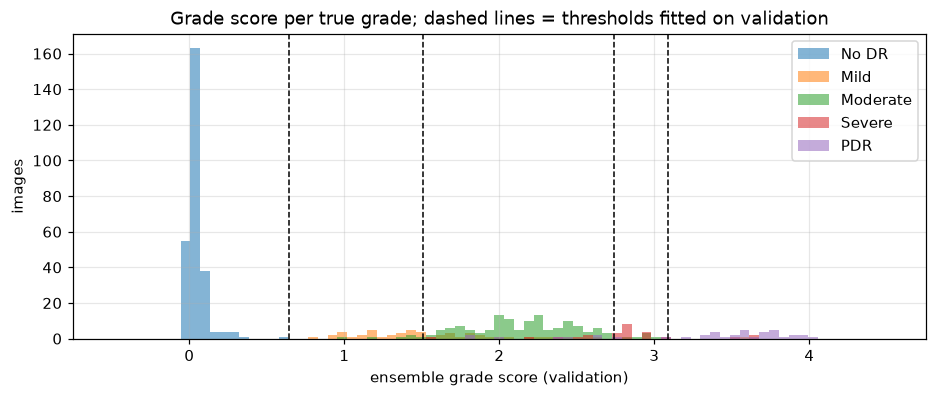

In [26]:
# ---- How the 4 thresholds cut the ensemble's grade score (validation) -------------------------------
thr = np.array(sel["thresholds"])
fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.linspace(-0.5, 4.5, 80)
for g in range(5):
    ax.hist(s_ens[y == g], bins=bins, alpha=0.55, label=GRADES[g])
for t in thr:
    ax.axvline(t, color="k", ls="--", lw=1)
ax.set_xlabel("ensemble grade score (validation)"); ax.set_ylabel("images"); ax.legend()
ax.set_title("Grade score per true grade; dashed lines = thresholds fitted on validation"); plt.show()

## 12. Stage G: the one-time test evaluation, plus external datasets

This was done **exactly once**, after `selection.json` was frozen. It produced:
* APTOS test results (525 images);
* IDRiD (all 508 gradable images) and Messidor-2 (all 1,740) as **never-seen** external datasets;
* 2,000-sample bootstrap 95% confidence intervals.

Once these numbers are seen, nothing is allowed to change. For example, the project did **not** switch to
ResNet-50 after it turned out to have higher test accuracy, because that would be selecting on test.

The switch `RUN_FINAL_TEST` stays `False`, and the saved results are loaded instead.

In [27]:
run("uv run python scripts/best_model.py --dataset aptos --final --external idrid messidor2", RUN_FINAL_TEST)
run("uv run python scripts/best_report.py --dataset aptos --external idrid messidor2", RUN_FINAL_TEST)

[skipped: switch is False]  $ uv run python scripts/best_model.py --dataset aptos --final --external idrid messidor2
[skipped: switch is False]  $ uv run python scripts/best_report.py --dataset aptos --external idrid messidor2


In [28]:
# ---- Headline results with 95% bootstrap CIs ---------------------------------------------------------
fm = load_json(EXP / "best_aptos" / "final_metrics.json")
rows = []
for name, e in fm["evaluations"].items():
    ci = e.get("ci95", {})
    fmt = lambda k: f"{e[k]:.3f}" + (f" [{ci[k][0]:.3f}–{ci[k][1]:.3f}]" if k in ci else "")
    rows.append({"evaluation": name, "n": e["n"], "accuracy": fmt("accuracy"), "QWK": fmt("qwk"),
                 "macro-F1": fmt("macro_f1"), "ref. sens": f"{e['referable_sensitivity']:.3f}",
                 "ref. spec": f"{e['referable_specificity']:.3f}", "ref. AUC": f"{e['referable_auc']:.3f}"})
v = fm["validation_cross_fitted"]
rows.insert(0, {"evaluation": "aptos_val (cross-fitted)", "n": v["n"], "accuracy": f"{v['accuracy']:.3f}",
                "QWK": f"{v['qwk']:.3f}", "macro-F1": f"{v['macro_f1']:.3f}",
                "ref. sens": f"{v['referable_sensitivity']:.3f}", "ref. spec": f"{v['referable_specificity']:.3f}",
                "ref. AUC": f"{v['referable_auc']:.3f}"})
pd.DataFrame(rows)

,evaluation,n,accuracy,QWK,macro-F1,ref. sens,ref. spec,ref. AUC
0,aptos_val (cross-fitted),524,0.903,0.953,0.802,0.975,0.935,0.985
1,aptos_test,525,0.846 [0.815–0.874],0.931 [0.913–0.947],0.683 [0.626–0.734],0.961,0.919,0.984
2,idrid_all,508,0.593 [0.549–0.636],0.819 [0.787–0.849],0.462 [0.420–0.504],0.808,0.995,0.976
3,messidor2_all,1740,0.661 [0.640–0.683],0.725 [0.694–0.752],0.434 [0.392–0.474],0.451,0.995,0.948


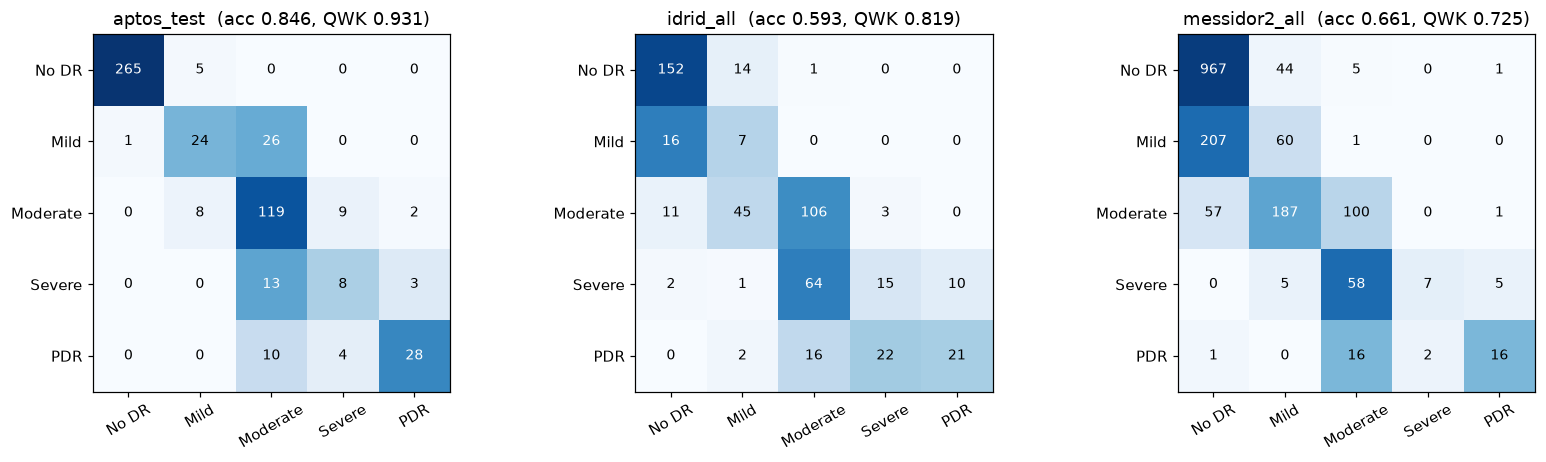

In [29]:
# ---- Confusion matrices (rows = true grade, columns = predicted grade) -------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, e) in zip(axes, fm["evaluations"].items()):
    cm = np.array(e["confusion_matrix"])
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] / max(cm[i].sum(), 1) > 0.5 else "black")
    ax.set_xticks(range(5), GRADES, rotation=30); ax.set_yticks(range(5), GRADES)
    ax.set_title(f"{name}  (acc {e['accuracy']:.3f}, QWK {e['qwk']:.3f})"); ax.grid(False)
plt.tight_layout(); plt.show()

In [30]:
# ---- Per-class results on APTOS test ----------------------------------------------------------------
pd.DataFrame(fm["evaluations"]["aptos_test"]["per_class"]).T

,precision,recall,f1,specificity,support
No DR,0.996,0.981,0.989,0.996,270.0
Mild,0.649,0.471,0.545,0.973,51.0
Moderate,0.708,0.862,0.778,0.873,138.0
Severe,0.381,0.333,0.356,0.974,24.0
PDR,0.848,0.667,0.747,0.990,42.0


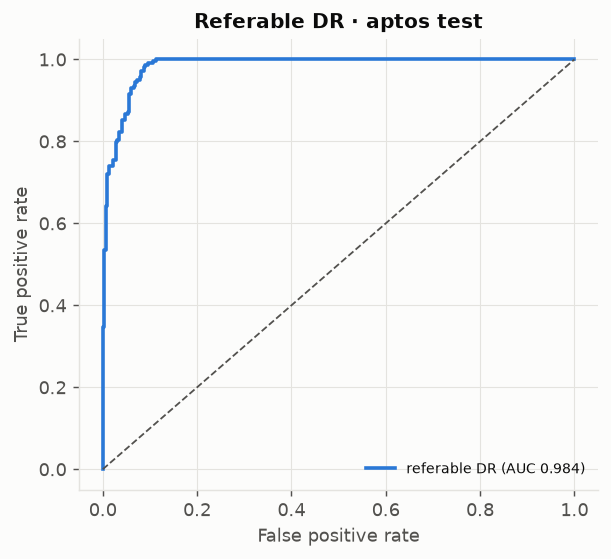

In [31]:
# ---- Referable-DR ROC curve (grade >= 2 needs referral to an ophthalmologist) --------------------------
display(Image(filename=str(PLOTS / "best_model" / "roc_referable_aptos_test.png"), width=520))

**Reading the external results**
* **IDRiD:** the five-class agreement (QWK 0.819) and referable AUC (0.976) hold up well.
* **Messidor-2:** the ranking is still good (AUC 0.948), but at the APTOS thresholds the model is too
  **conservative**, with referable sensitivity of only 0.45. This is a calibration shift between sites,
  not a failure to see lesions. The EyePACS-trained models (next section) transfer much better.

## 13. Stage H: baselines on test, cross-dataset results and statistics

Each frozen baseline was also evaluated **once** on APTOS test and on IDRiD, so every reproduced paper model
has a full test row. The feature models (RF, SVM) refit their validation-chosen classifier with fixed seeds.

In [32]:
run("uv run python scripts/final_baselines.py", RUN_BASELINE_TEST)
run("uv run python scripts/train_features.py --model resnet50_rf --dataset aptos "
    "--cnn_ckpt checkpoints/resnet50_rf__aptos__5class__raw_384_s42.pt --final", RUN_BASELINE_TEST)
run("uv run python scripts/train_features.py --model hybrid_svm --dataset aptos --task 5class --final", RUN_BASELINE_TEST)
for c in ["effb3_se__eyepacs__5class__ben_graham_512_s42", "densenet169__eyepacs__5class__raw_384_s42",
          "resnet50_rf__eyepacs__5class__raw_384_s42"]:
    run(f"uv run python scripts/evaluate.py --ckpt checkpoints/{c}.pt --dataset messidor2 --split all", RUN_BASELINE_TEST)
run("uv run python scripts/compare_models.py --split test", RUN_BASELINE_TEST)
run("uv run python scripts/compare_models.py --split val", RUN_BASELINE_TEST)

[skipped: switch is False]  $ uv run python scripts/final_baselines.py
[skipped: switch is False]  $ uv run python scripts/train_features.py --model resnet50_rf --dataset aptos --cnn_ckpt checkpoints/resnet50_rf__aptos__5class__raw_384_s42.pt --final
[skipped: switch is False]  $ uv run python scripts/train_features.py --model hybrid_svm --dataset aptos --task 5class --final
[skipped: switch is False]  $ uv run python scripts/evaluate.py --ckpt checkpoints/effb3_se__eyepacs__5class__ben_graham_512_s42.pt --dataset messidor2 --split all
[skipped: switch is False]  $ uv run python scripts/evaluate.py --ckpt checkpoints/densenet169__eyepacs__5class__raw_384_s42.pt --dataset messidor2 --split all
[skipped: switch is False]  $ uv run python scripts/evaluate.py --ckpt checkpoints/resnet50_rf__eyepacs__5class__raw_384_s42.pt --dataset messidor2 --split all
[skipped: switch is False]  $ uv run python scripts/compare_models.py --split test
[skipped: switch is False]  $ uv run python scripts/com

In [33]:
# ---- Test-set comparison: every paper baseline and the final ensemble (last row) -----------------
cmp_ = pd.read_csv(REP / "model_comparison.csv")
cols = ["run", "paper", "params", "inference_ms", "accuracy", "macro_f1", "qwk", "roc_auc",
        "referable_sensitivity", "referable_specificity", "ext_idrid_qwk"]
cmp_[[c for c in cols if c in cmp_]].assign(params=lambda d: (d.params / 1e6).round(1)).rename(columns={"params": "params_M"})

,run,paper,params_M,inference_ms,accuracy,macro_f1,qwk,roc_auc,referable_sensitivity,referable_specificity,ext_idrid_qwk
0,densenet169__aptos__5class__raw_384_s42,P14,12.5,5.591,0.836,0.654,0.904,0.944,0.902,0.944,0.744
1,effb3_se__aptos__5class__ben_graham_384_s42,P4,11.0,22.848,0.821,0.675,0.903,0.950,0.936,0.919,0.748
2,hybrid_svm__aptos__5class,P6,18.3,1.315,0.819,0.594,0.850,0.922,0.912,0.941,NaN
3,inception_v3__aptos__5class__raw_384_s42,P7,21.8,3.753,0.829,0.687,0.898,0.942,0.926,0.925,0.790
4,light2stage__aptos__5class_combined_s42,P10,1.6,NaN,0.750,0.398,0.733,0.868,0.779,0.925,0.482
5,mil_resnet18__aptos__5class__graham_rim_512_s42,P12,11.2,46.669,0.815,0.631,0.874,0.940,0.848,0.950,0.688
6,mscnn_lstm__aptos__5class__clahe_224_s42,P15,1.9,2.401,0.741,0.405,0.788,0.881,0.882,0.882,0.512
7,p8_vgg16__aptos__5class__agc_p8_384_s42,P8,134.3,10.646,0.815,0.646,0.886,0.933,0.912,0.916,0.769
8,resnet50_rf__aptos__5class,P11,23.5,0.084,0.844,0.671,0.902,0.949,0.946,0.928,NaN
9,resnet50_rf__aptos__5class__raw_384_s42,P11,23.5,4.283,0.861,0.743,0.911,0.952,0.887,0.956,0.746


In [34]:
# ---- Cross-dataset: which training data generalises better to a new site? ------------------------------
xd = pd.read_csv(REP / "cross_dataset.csv")
display(xd)
# EyePACS-trained models (many sites) vs the APTOS-trained ensemble, on Messidor-2:
display(xd[xd.test.str.contains("Messidor")][["train", "model", "qwk", "referable_sensitivity", "referable_auc"]])

,train,test,model,paper,n,accuracy,macro_f1,qwk,roc_auc,referable_sensitivity,referable_specificity,referable_auc
0,APTOS,IDRiD (all 508),densenet169,P14,508,0.520,0.444,0.744,0.836,0.818,0.937,0.956
1,APTOS,IDRiD (all 508),effb3_se,P4,508,0.577,0.481,0.748,0.816,0.874,0.826,0.942
2,APTOS,IDRiD (all 508),inception_v3,P7,508,0.575,0.445,0.790,0.818,0.802,0.974,0.966
3,APTOS,IDRiD (all 508),light2stage,P10,508,0.376,0.245,0.482,0.745,0.594,0.989,0.908
4,APTOS,IDRiD (all 508),mil_resnet18,P12,508,0.470,0.385,0.688,0.850,0.755,0.979,0.959
5,APTOS,IDRiD (all 508),mscnn_lstm,P15,508,0.453,0.259,0.512,0.690,0.582,1.000,0.928
6,APTOS,IDRiD (all 508),p8_vgg16,P8,508,0.596,0.469,0.769,0.795,0.818,0.963,0.966
7,APTOS,IDRiD (all 508),resnet50_rf,P11,508,0.520,0.430,0.746,0.833,0.811,0.947,0.954
8,APTOS,IDRiD (all 508),vit_b16,P14,508,0.400,0.332,0.640,0.762,0.780,0.963,0.919
9,APTOS,IDRiD (all 508),BEST ENSEMBLE,—,508,0.593,0.462,0.819,0.858,0.808,0.995,0.976


,train,model,qwk,referable_sensitivity,referable_auc
10,EyePACS,densenet169,0.785,0.868,0.953
11,EyePACS,effb3_se,0.756,0.923,0.967
12,EyePACS,resnet50_rf,0.784,0.884,0.963
13,APTOS,BEST ENSEMBLE,0.725,0.451,0.948


In [35]:
# ---- Paired comparison on APTOS test: ensemble vs best single model (ResNet-50) ------------------------
# McNemar's exact test on images that exactly one of the two classifies correctly. This is reporting only:
# nothing is selected from it.
from scipy.stats import binomtest
from sklearn.metrics import cohen_kappa_score

def test_preds(stem):
    d = np.load(PRED / f"{stem}__aptos_test_tta4.npz", allow_pickle=True)
    return d["y"], d["prob"], d["raw"]

yt, _, _ = test_preds(stems[0])
uid_t = np.load(PRED / f"{stems[0]}__aptos_test_tta4.npz", allow_pickle=True)["uid"]
s_test = np.mean([test_preds(s)[2] for s in stems], axis=0)
ens_pred = cut(s_test, np.array(sel["thresholds"]))
# ResNet-50 exactly as it was evaluated once on test (its own run folder, no TTA), aligned by image id.
r = np.load(EXP / "resnet50_rf__aptos__5class__raw_384_s42" / "test_predictions.npz", allow_pickle=True)
order = pd.Series(np.arange(len(r["uid"])), index=r["uid"]).loc[uid_t].values
r50_pred = r["prob"][order].argmax(1)
assert (r["y"][order] == yt).all()

a_ok, b_ok = ens_pred == yt, r50_pred == yt
n01, n10 = int((~a_ok & b_ok).sum()), int((a_ok & ~b_ok).sum())
print(f"accuracy  ensemble {a_ok.mean():.3f} | ResNet-50 {b_ok.mean():.3f}")
print(f"QWK       ensemble {cohen_kappa_score(yt, ens_pred, weights='quadratic'):.3f} | "
      f"ResNet-50 {cohen_kappa_score(yt, r50_pred, weights='quadratic'):.3f}")
print(f"McNemar: ensemble-only correct {n10}, ResNet-only correct {n01}, "
      f"exact p = {binomtest(n10, n10 + n01, 0.5).pvalue:.2f}")

accuracy  ensemble 0.846 | ResNet-50 0.861
QWK       ensemble 0.931 | ResNet-50 0.911
McNemar: ensemble-only correct 28, ResNet-only correct 36, exact p = 0.38


The ensemble's QWK is higher, but the accuracy difference against ResNet-50 is **not statistically
significant** (exact McNemar p = 0.38). The paper reports the ensemble as the *validation-selected* model, together with
this caveat.

## 14. Stage I: packaged model and inference on new images

`best_model/` holds the 4 member checkpoints and `model_card.json`, which lists the members, thresholds,
TTA and preprocessing. The weights are not in git; they are attached to the
[GitHub release v1.0](https://github.com/nik1856nik/leakage-free-dr-grading/releases/tag/v1.0):

```bash
gh release download v1.0 -D best_model && (cd best_model && sha256sum -c SHA256SUMS.txt)
```

`scripts/predict.py` applies the exact training pipeline to any fundus photo:
retina crop → 512 px → JPEG round trip → each member's enhancement → 4 flips → average → thresholds.
It was checked to reproduce the evaluated test grades exactly (40/40).

In [36]:
# ---- Grade a few raw APTOS test photos with the packaged ensemble ------------------------------------
card = load_json(ROOT / "best_model" / "model_card.json")
have_weights = all((ROOT / "best_model" / m["checkpoint"]).exists() for m in card["members"])
raw_dir = ROOT / "data" / "raw" / "aptos2019"
test_ids = splits["aptos"].query("split == 'test'").groupby("label").head(1)      # one image per grade
files = [next(raw_dir.rglob(u.split("/")[1] + ".png"), None) for u in test_ids.uid]

if RUN_INFERENCE_DEMO and have_weights and all(files):
    out_csv = ROOT / "experiments" / "notebook_predictions.csv"   # demo output (not part of any result)
    rel = lambda p: shlex.quote(str(Path(p).relative_to(ROOT)))
    run("uv run python scripts/predict.py " + " ".join(rel(f) for f in files) + f" --csv {rel(out_csv)}")
    pred = pd.read_csv(out_csv)
    pred["true_grade"] = test_ids.label.values
    display(pred[["image", "true_grade", "grade", "grade_name", "grade_score", "p_referable", "referable"]]
            .assign(image=lambda d: d.image.map(lambda p: Path(p).name)))
else:
    print("Skipped: needs RUN_INFERENCE_DEMO=True, the 4 weights in best_model/ and the raw APTOS images.")

$ uv run python scripts/predict.py data/raw/aptos2019/train_images/0024cdab0c1e.png data/raw/aptos2019/train_images/0151781fe50b.png data/raw/aptos2019/train_images/0161338f53cc.png data/raw/aptos2019/train_images/02dda30d3acf.png data/raw/aptos2019/train_images/03c85870824c.png --csv experiments/notebook_predictions.csv


                                           image  grade grade_name  grade_score  p_referable referable
data/raw/aptos2019/train_images/0024cdab0c1e.png      1       Mild        0.849       0.1132        no
data/raw/aptos2019/train_images/0151781fe50b.png      0      No DR       -0.003       0.0002        no
data/raw/aptos2019/train_images/0161338f53cc.png      2   Moderate        1.956       0.8536     REFER
data/raw/aptos2019/train_images/02dda30d3acf.png      4        PDR        3.855       0.9927     REFER
data/raw/aptos2019/train_images/03c85870824c.png      2   Moderate        2.720       0.9235     REFER
saved experiments/notebook_predictions.csv


,image,true_grade,grade,grade_name,grade_score,p_referable,referable
0,0024cdab0c1e.png,1,1,Mild,0.849,1.132e-01,no
1,0151781fe50b.png,0,0,No DR,-0.003,2.000e-04,no
2,0161338f53cc.png,2,2,Moderate,1.956,8.536e-01,REFER
3,02dda30d3acf.png,4,4,PDR,3.855,9.927e-01,REFER
4,03c85870824c.png,3,2,Moderate,2.720,9.235e-01,REFER


## 15. Interpretability: Grad-CAM

Grad-CAM on the EfficientNet-B3 classifier member shows **where** the network looks. For correct
high-grade predictions, it focuses on haemorrhages, exudates and new vessels. The typical errors are
Mild and Severe cases predicted as Moderate, where the boundaries between grades are genuinely ambiguous.

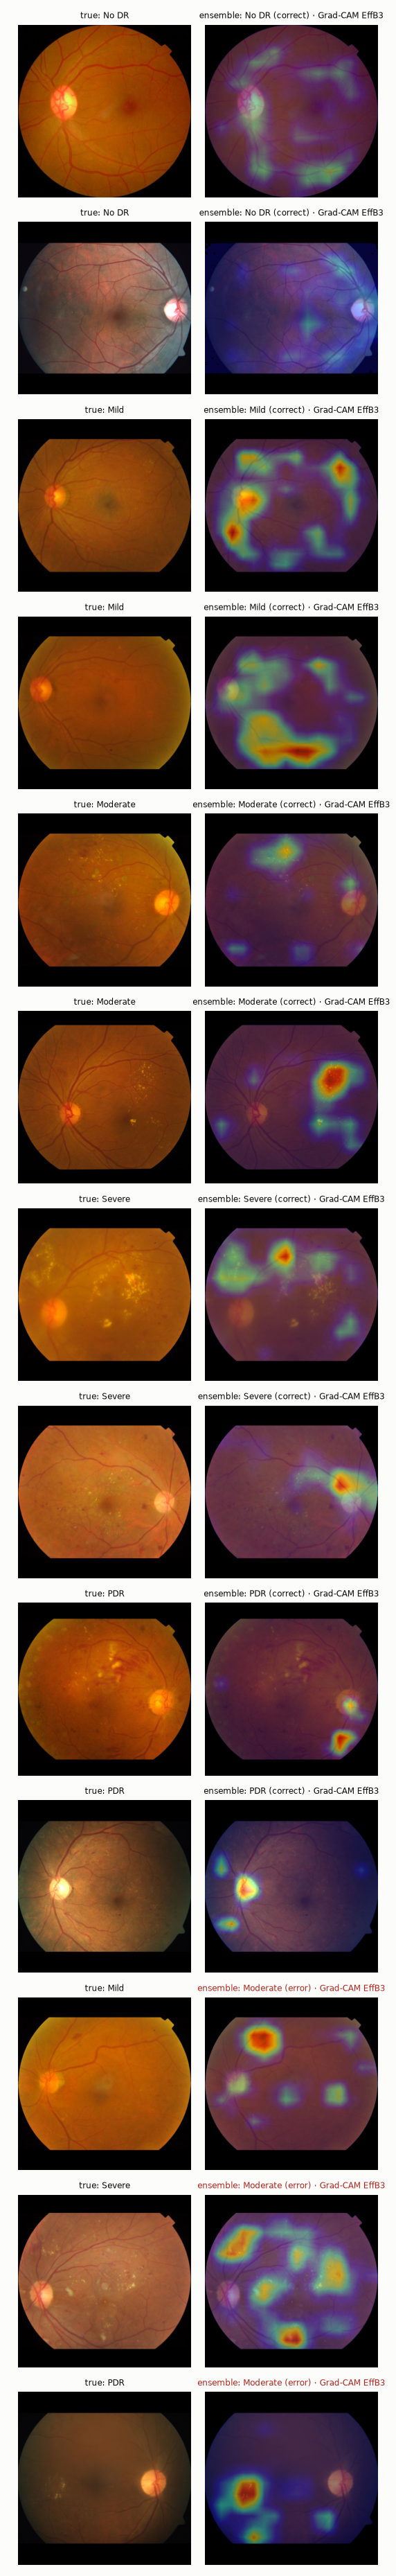

In [37]:
display(Image(filename=str(PLOTS / "best_model" / "gradcam_effb3_test_examples.png"), width=900))

## 16. Paper and reports

* `reports/final_report.md`: the complete results and discussion.
* `reports/replication_guide.md`: every command, with the reasoning behind it.
* `paper/main.pdf`: the IEEE-format paper. `paper/main(bw).pdf` is the black-and-white print copy.

The figures and the PDF are rebuilt from the saved results:

In [38]:
run("uv run python paper/make_figures.py && uv run python paper/make_figures_extra.py", RUN_PAPER_BUILD)
run("cd paper && ~/.local/bin/tectonic main.tex", RUN_PAPER_BUILD)

[skipped: switch is False]  $ uv run python paper/make_figures.py && uv run python paper/make_figures_extra.py
[skipped: switch is False]  $ cd paper && ~/.local/bin/tectonic main.tex


## 17. Summary

| | APTOS test (once) | IDRiD (external) | Messidor-2 (external) |
|---|---|---|---|
| Accuracy | **0.846** [0.815–0.874] | 0.593 | 0.661 |
| QWK | **0.931** [0.913–0.947] | 0.819 | 0.725 |
| Referable DR | sens 0.961 · spec 0.919 · AUC 0.984 | AUC 0.976 | AUC 0.948 (sens 0.45) |

**What we conclude**
1. With leakage controlled (duplicate audit and grouped splits), a validation-selected ensemble of
   different architectures and head types reaches QWK 0.931 and referable-DR AUC 0.984 on an untouched
   APTOS test set.
2. Its gain over the best single model is small and not significant, about the size of seed noise. Honest
   reporting matters more than a leaderboard number.
3. Transfer to a new site depends mostly on the **training data**. EyePACS-trained models transfer to
   Messidor-2 far better than APTOS-trained ones, so threshold recalibration per site is needed before any
   clinical use.

*Research use only. This is not a medical device.*